# 量子随机数 · 模拟熵管线、健康诊断与提取

QuantumBridge / 量子安全 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 本批没有真实硬件熵源或认证；未提供安全随机数服务。示意检测不能替代熵估计、源失效处理、设备溯源及安全认证。

## 1. 原理与计算对象

本地 RY 电路产生 P(1)=0.72 的已知偏置，按固定种子保留 4096 个有序样本。必须保留顺序才能做连续重复和窗口频数诊断；不能从汇总 counts 拼出顺序。
采用 Von Neumann 成对去偏：01→0，10→1，00/11 丢弃。若输入独立同分布，01 和 10 都有概率 p(1-p)，于是输出理论上均衡，平均输出长度占输入长度比例为 p(1-p)。关联源不满足此保证。

最长重复与 128 样本窗口的阈值是**显式示意诊断阈值，不是 NIST 800-90B 认证配置**。频率接近 1/2、通过诊断或做过提取都不能证明有物理熵；确定性模拟器输出仍是伪随机。

## 2. 实现步骤

1. 构建偏置 RY 电路并获取有序本地样本。
2. 显示原始流、最长重复与各窗口 ones 数。
3. 逐对提取并记录输出长度和偏置变化。
4. 比较计数图、理论均值与独立的 1024 shots 观测。
5. 明确物理熵声明为 false，不生成生产随机数服务或虚构真机回执。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import copy
import hashlib
import hmac
import json
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.finance.kernels import labels
from quantumbridge.applications.common import ApplicationCase

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def von_neumann_extract(bits):
    values = list(bits)
    if any(bit not in (0, 1) for bit in values):
        raise ValueError("Binary symbols are required.")
    return [a for a, b in zip(values[::2], values[1::2]) if a != b]


def stream_health(bits):
    values = list(bits)
    if not values or any(bit not in (0, 1) for bit in values):
        raise ValueError("A nonempty binary stream is required.")
    longest, run = 1, 1
    for previous, value in zip(values, values[1:]):
        run = run + 1 if value == previous else 1
        longest = max(longest, run)
    windows = [
        {
            "window": i // 128,
            "samples": len(values[i : i + 128]),
            "ones": sum(values[i : i + 128]),
        }
        for i in range(0, len(values), 128)
    ]
    ok = longest < 32 and all(
        32 <= row["ones"] <= 112 for row in windows if row["samples"] == 128
    )
    return {
        "max_run": longest,
        "illustrative_repeat_limit": 32,
        "illustrative_window_ones_bounds": [32, 112],
        "diagnostics_pass": ok,
        "windows": windows,
        "nist_90b_certified": False,
    }


def qrng_case():
    probability = 0.72
    circuit = Circuit(1, name="biased-qrng-simulation").ry(
        2 * np.arcsin(np.sqrt(probability)), 0
    )
    raw = [
        int(bit)
        for bit in StatevectorDevice().sample(circuit, shots=4096, seed=20261023)
    ]
    extracted, health = von_neumann_extract(raw), stream_health(raw)
    return ApplicationCase(
        "qrng",
        "security",
        "Simulated entropy pipeline, health diagnostics and extraction",
        {
            "source": "seeded local statevector simulation",
            "raw_samples": 4096,
            "seed": 20261023,
            "one_probability": probability,
            "extractor": "01 -> 0; 10 -> 1; 00/11 discarded; unpaired tail discarded",
        },
        {
            "ordered_raw_stream": "".join(map(str, raw)),
            "extracted_stream": "".join(map(str, extracted)),
            "health": health,
            "window_statistics": health["windows"],
            "chart_rows": [
                {"label": "Raw zeros", "value": raw.count(0)},
                {"label": "Raw ones", "value": sum(raw)},
                {"label": "Extracted zeros", "value": extracted.count(0)},
                {"label": "Extracted ones", "value": sum(extracted)},
            ],
            "chart_units": "Bit count",
            "chart_title": "Biased simulated stream and Von Neumann output",
        },
        {
            "ideal_input_one_probability": probability,
            "ideal_output_one_probability_under_iid_assumption": 0.5,
            "expected_output_fraction_of_input": probability * (1 - probability),
        },
        {"biased_sampling": circuit},
        {"biased_sampling": [0.0, 1.0]},
        {
            "raw_ones_fraction": sum(raw) / len(raw),
            "extracted_length": len(extracted),
            "extracted_ones_fraction": sum(extracted) / len(extracted)
            if extracted
            else None,
            "diagnostics_pass": health["diagnostics_pass"],
            "physical_entropy_claim": False,
            "production_random_bytes_emitted": False,
            "hardware_receipt": None,
        },
    )


In [3]:
case = qrng_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

window,samples,ones
0,128,88
1,128,86
2,128,101
3,128,89
4,128,97
5,128,87
6,128,89
7,128,94
8,128,91
9,128,83


label,value
Raw zeros,1207
Raw ones,2889
Extracted zeros,430
Extracted ones,425


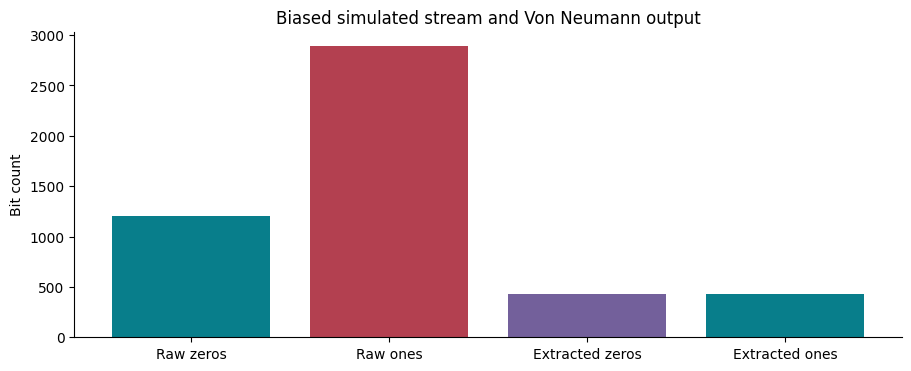

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
biased_sampling,1,1,1024,20261023


observable,estimate,standard_error,ideal_reference
biased_sampling,0.71386719,0.014130409,0.72


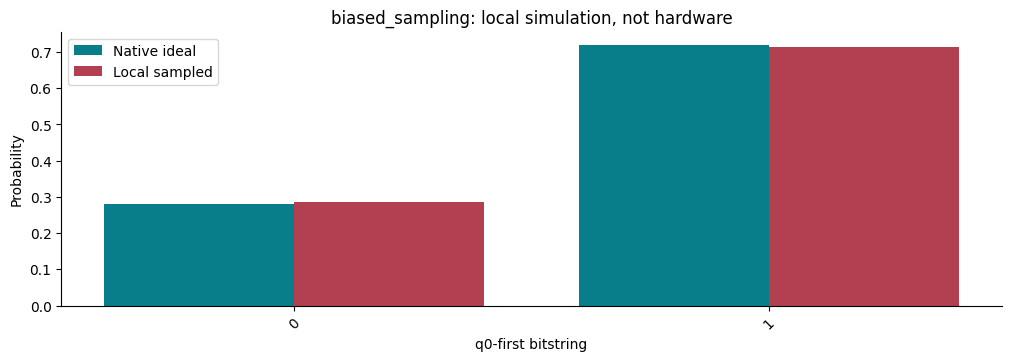

experiment,counts
biased_sampling,"{""1"": 731, ""0"": 293}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- biased_sampling ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[1];
creg c[1];
ry(2.0263950001907198) q[0];
measure q[0] -> c[0];



## 8. 结果解释、复做与非目标

中间的 4096 位有序流和最后 1024 shots 测量是不同展示对象。extracted_ones_fraction 接近 0.5 仅说明去偏效果，不表示得到安全密钥或真实量子熵。

本批没有真实硬件熵源或认证；未提供安全随机数服务。示意检测不能替代熵估计、源失效处理、设备溯源及安全认证。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/security/04_qrng_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 04_qrng_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [NIST SP 800-90B 熵源要求](https://csrc.nist.gov/pubs/sp/800/90/b/final)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。